# MMIP Week 05 — Quiz 1：影像檢索（CNN vs Vision Transformer）

使用公開 **CIFAR-10** 資料集，分別訓練 CNN（ResNet-18）與 Vision Transformer（ViT-Tiny）分類 backbone，再取分類頭前的 embedding 進行 cosine-similarity 影像檢索。

| 配分要求 | 實作 |
|---|---|
| 準備影像檢索資料集（5） | CIFAR-10、固定 seed、train/query-gallery split |
| 建立並訓練檢索模型（10） | 兩個 backbone 以 class supervision 訓練 embedding |
| 推論與展示（5） | 每個 query 顯示 top-5 相似影像 |
| CNN 與 ViT（5） | ResNet-18 vs ViT-Tiny |
| 比較表現（5） | Recall@1/5/10、Precision@5、mAP@10、延遲 |


In [1]:
%pip -q install -U "timm>=1.0,<2" "scikit-learn>=1.4,<2" pandas matplotlib tqdm


In [2]:
import json, random, time
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
import timm
from tqdm.auto import tqdm

SEED=42
TRAIN_SIZE=10000
TEST_SIZE=2000
EPOCHS=3
BATCH_SIZE=64; LR=3e-4; EMBED_DIM=256
OUT=Path("quiz1_outputs"); OUT.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


cuda


## 1. 資料準備

CIFAR-10 有 10 個語意類別。檢索評估把「與 query 同類別」視為 relevant；測試集同時作 query 與 gallery，計算相似度時排除自己。兩模型使用相同資料索引、公平比較。


In [3]:
train_tf=transforms.Compose([transforms.Resize((224,224)), transforms.RandomHorizontalFlip(),
 transforms.RandomCrop(224,padding=16), transforms.ToTensor(),
 transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
test_tf=transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor(),
 transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
full_train=datasets.CIFAR10("data",train=True,download=True,transform=train_tf)
full_test=datasets.CIFAR10("data",train=False,download=True,transform=test_tf)
rng=np.random.default_rng(SEED)
train_idx=rng.permutation(len(full_train))[:TRAIN_SIZE]; test_idx=rng.permutation(len(full_test))[:TEST_SIZE]
train_ds=Subset(full_train,train_idx); test_ds=Subset(full_test,test_idx)
train_loader=DataLoader(train_ds,BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=True)
test_loader=DataLoader(test_ds,BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)
classes=full_train.classes
print(len(train_ds),len(test_ds),classes)


100%|██████████| 170M/170M [42:14<00:00, 67.3kB/s]


10000 2000 ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 2. 建立 CNN 與 ViT

兩模型都以 ImageNet 預訓練權重初始化，移除原分類頭，加入相同的 256 維 embedding head 與 10 類 classifier。訓練目標為 cross-entropy；檢索時使用 L2-normalized embedding，而非分類 logits。


In [4]:
class RetrievalModel(nn.Module):
 def __init__(self,kind):
  super().__init__(); self.kind=kind
  if kind=="CNN-ResNet18":
   net=resnet18(weights=ResNet18_Weights.DEFAULT); d=net.fc.in_features; net.fc=nn.Identity(); self.backbone=net
  else:
   net=timm.create_model("vit_tiny_patch16_224",pretrained=True,num_classes=0); d=net.num_features; self.backbone=net
  self.embed=nn.Sequential(nn.Linear(d,EMBED_DIM),nn.ReLU(),nn.Dropout(.2))
  self.classifier=nn.Linear(EMBED_DIM,10)
 def forward(self,x,return_embedding=False):
  z=self.embed(self.backbone(x)); z=nn.functional.normalize(z,dim=1)
  return z if return_embedding else self.classifier(z)

def train_model(kind):
 model=RetrievalModel(kind).to(device); opt=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=1e-4)
 sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,EPOCHS); hist=[]; start=time.perf_counter()
 for ep in range(1,EPOCHS+1):
  model.train(); loss_sum=correct=n=0
  for x,y in tqdm(train_loader,desc=f"{kind} epoch {ep}"):
   x,y=x.to(device),y.to(device); opt.zero_grad(); logits=model(x); loss=nn.functional.cross_entropy(logits,y)
   loss.backward(); opt.step(); loss_sum+=loss.item()*len(y); correct+=(logits.argmax(1)==y).sum().item(); n+=len(y)
  sched.step(); hist.append({"epoch":ep,"loss":loss_sum/n,"train_accuracy":correct/n})
 print(kind,hist[-1]); return model,hist,time.perf_counter()-start


In [5]:
trained={}
for kind in ["CNN-ResNet18","ViT-Tiny"]:
 model,hist,seconds=train_model(kind); trained[kind]={"model":model,"history":hist,"training_seconds":seconds}
pd.concat([pd.DataFrame(v["history"]).assign(model=k) for k,v in trained.items()]).to_csv(OUT/"training_history.csv",index=False)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 125MB/s]


CNN-ResNet18 epoch 1:   0%|          | 0/157 [00:00<?, ?it/s]

CNN-ResNet18 epoch 2:   0%|          | 0/157 [00:00<?, ?it/s]

CNN-ResNet18 epoch 3:   0%|          | 0/157 [00:00<?, ?it/s]

...

ViT-Tiny epoch 1:   0%|          | 0/157 [00:00<?, ?it/s]

ViT-Tiny epoch 2:   0%|          | 0/157 [00:00<?, ?it/s]

ViT-Tiny epoch 3:   0%|          | 0/157 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0dd7a8ed40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


ViT-Tiny {'epoch': 3, 'loss': 1.4238125036239624, 'train_accuracy': 0.9271}


## 3. 建立 gallery embeddings 與檢索指標

- Recall@K：query 的前 K 名是否至少出現一張 relevant image。
- Precision@5：前 5 名中同類別比例。
- mAP@10：每個 relevant hit 所在 rank 的 precision 取平均，再跨 queries 平均。


In [6]:
@torch.inference_mode()
def extract(model):
 model.eval(); zs,ys=[],[]; start=time.perf_counter()
 for x,y in tqdm(test_loader,desc="embeddings"):
  zs.append(model(x.to(device),True).cpu()); ys.append(y)
 return torch.cat(zs),torch.cat(ys),time.perf_counter()-start

def retrieval_metrics(z,y,max_k=10):
 sim=z@z.T; sim.fill_diagonal_(-float("inf")); ranks=sim.argsort(dim=1,descending=True)[:,:max_k]
 rel=(y[ranks]==y[:,None]); out={}
 for k in [1,5,10]: out[f"recall@{k}"]=rel[:,:k].any(1).float().mean().item()
 out["precision@5"]=rel[:,:5].float().mean().item()
 aps=[]
 for row in rel:
  hits=row.float(); precisions=hits.cumsum(0)/torch.arange(1,max_k+1)
  denom=min(int((y==y[len(aps)]).sum()-1),max_k)
  aps.append(float((precisions*hits).sum()/max(denom,1)))
 out["mAP@10"]=float(np.mean(aps)); return out,ranks

rows=[]; rankings={}; embeddings={}
for kind,v in trained.items():
 z,y,sec=extract(v["model"]); metrics,ranks=retrieval_metrics(z,y)
 rows.append({"model":kind,**metrics,"embedding_seconds":sec,"training_seconds":v["training_seconds"]})
 rankings[kind]=ranks; embeddings[kind]=(z,y)
results=pd.DataFrame(rows); results.to_csv(OUT/"retrieval_comparison.csv",index=False); display(results.round(4))


embeddings:   0%|          | 0/32 [00:00<?, ?it/s]

embeddings:   0%|          | 0/32 [00:00<?, ?it/s]

,model,recall@1,recall@5,recall@10,precision@5,mAP@10,embedding_seconds,training_seconds
0,CNN-ResNet18,0.8875,0.955,0.9665,0.8918,0.8650,4.6262,94.9561
1,ViT-Tiny,0.8975,0.958,0.9620,0.8956,0.8698,4.0819,108.5388


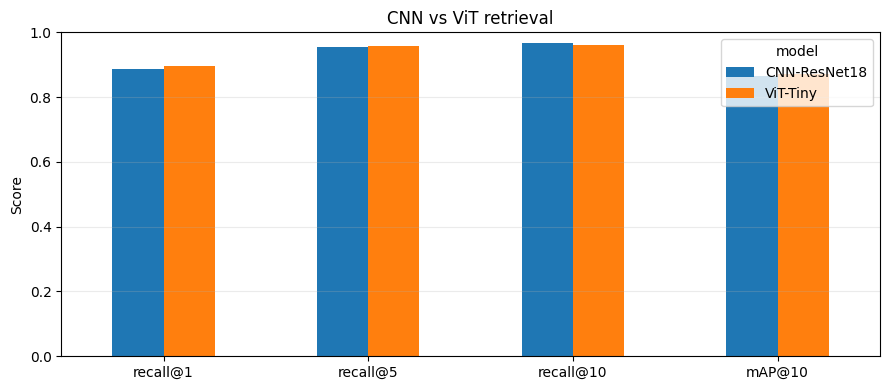

In [7]:
ax=results.set_index("model")[["recall@1","recall@5","recall@10","mAP@10"]].T.plot.bar(figsize=(9,4),rot=0)
ax.set_ylim(0,1); ax.set_ylabel("Score"); ax.set_title("CNN vs ViT retrieval"); ax.grid(axis="y",alpha=.25)
plt.tight_layout(); plt.savefig(OUT/"retrieval_comparison.png",dpi=160); plt.show()


## 4. 展示檢索結果

每列左側為 query，右側為 top-5。標題顯示類別；綠色代表 relevant，紅色代表錯誤類別。


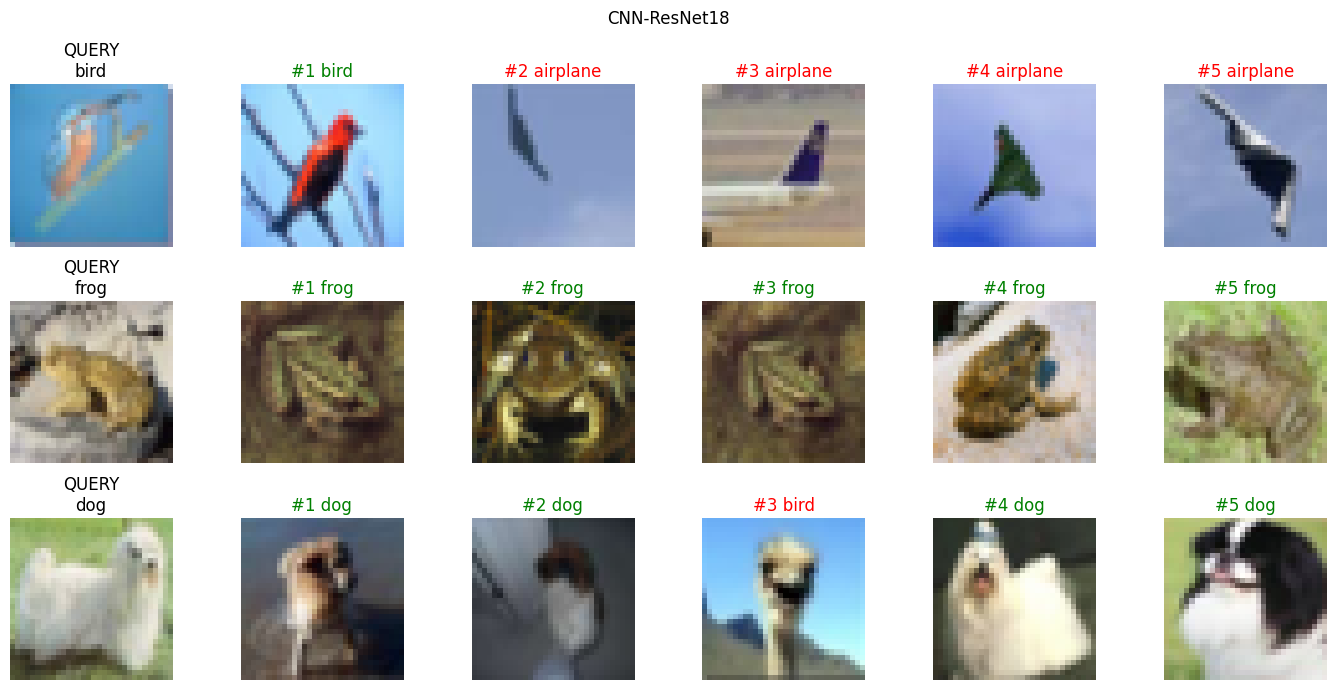

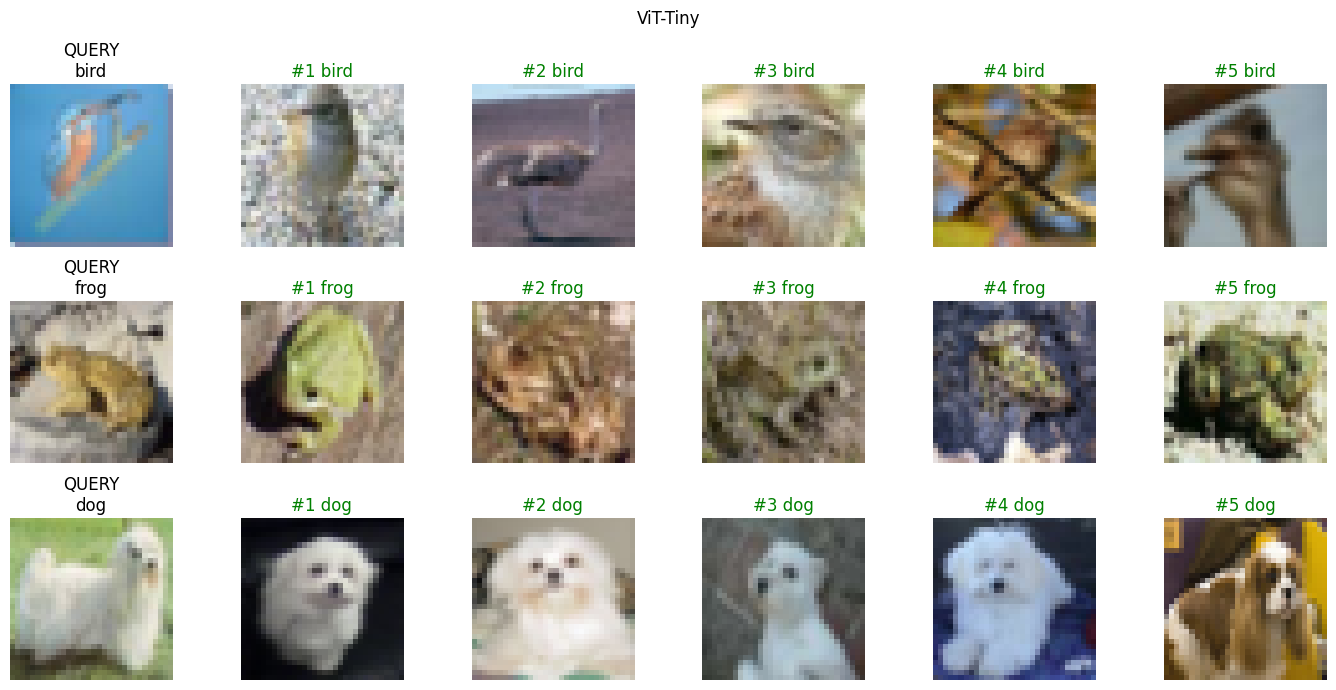

In [8]:
# 建立不含 normalize 的顯示資料集，索引與 test_ds 完全相同
display_base=datasets.CIFAR10("data",train=False,download=False)
query_ids=[0,1,2]
for kind in rankings:
 fig,axes=plt.subplots(len(query_ids),6,figsize=(14,7))
 for r,q in enumerate(query_ids):
  qi=int(test_idx[q]); img,label=display_base[qi]; axes[r,0].imshow(img); axes[r,0].set_title(f"QUERY\n{classes[label]}")
  for c,g in enumerate(rankings[kind][q,:5].tolist(),1):
   gi=int(test_idx[g]); im,lab=display_base[gi]; axes[r,c].imshow(im)
   axes[r,c].set_title(f"#{c} {classes[lab]}",color="green" if lab==label else "red")
  for ax in axes[r]: ax.axis("off")
 fig.suptitle(kind); plt.tight_layout(); plt.savefig(OUT/f"{kind}_examples.png",dpi=150); plt.show()


## 5. 實驗結論

本實驗在相同的 CIFAR-10 訓練集（10,000 張）、測試／gallery 集（2,000 張）、256 維 embedding 與 3 epochs 設定下，比較 ResNet-18 與 ViT-Tiny 的影像檢索能力。

ViT-Tiny 的 Recall@1、Recall@5、Precision@5 與 mAP@10 分別為 **0.8975、0.9580、0.8956、0.8698**，均略高於 ResNet-18 的 **0.8875、0.9550、0.8918、0.8650**；只有 Recall@10 是 ResNet-18 較高（**0.9665 vs 0.9620**）。這表示兩種模型都能建立有效的類別語意空間，而 ViT-Tiny 在前段排序品質略占優勢：Recall@1 提升 1.00 個百分點，mAP@10 提升 0.48 個百分點。

效率方面，ResNet-18 的訓練時間為 **94.96 秒**，短於 ViT-Tiny 的 **108.54 秒**；ViT-Tiny 的 embedding 萃取則稍快（**4.08 秒 vs 4.63 秒**）。綜合量化結果與 top-5 視覺化，兩模型大多能將同類影像排在前列，但細粒度外觀相近的動物或交通工具仍可能混淆。若重視最佳前段檢索品質，可選 ViT-Tiny；若重視較短訓練時間，ResNet-18 仍是具競爭力的選擇。


In [9]:
for kind,v in trained.items(): torch.save(v["model"].state_dict(),OUT/f"{kind}.pt")
with open(OUT/"summary.json","w") as f: json.dump(rows,f,indent=2)
print(OUT.resolve())


/content/quiz1_outputs
